In [28]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("train.csv")

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (159571, 8)


In [4]:
print("Columns:", df.columns.tolist())

Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [5]:
df.head(9)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\r\nWhy the edits made under my use...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\r\nMore\r\nI can't make any real suggestions...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\r\n\r\nCongratulations from me as well, use ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0


#### Checking Null Values:

In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


#### Checking Duplicates:

In [7]:
print("Duplicate comment texts:",
      df["comment_text"].duplicated().sum())

Duplicate comment texts: 0


In [8]:
# 3. Label distribution
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("Positive examples per label:")
print(df[labels].sum().sort_values(ascending=False))
## rakhne ki trick:
## ascending=True → chhote se bade
## ascending=False → bade se chhote

Positive examples per label:
toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64


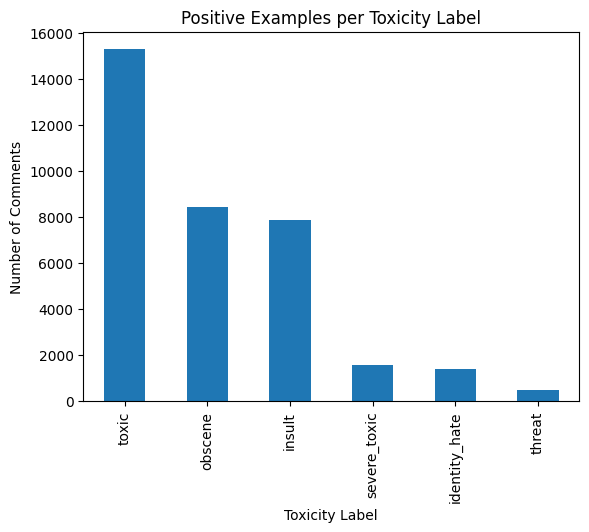

In [9]:
df[labels].sum().sort_values(ascending=False).plot(
    kind="bar",
    title="Positive Examples per Toxicity Label",
    xlabel="Toxicity Label",
    ylabel="Number of Comments"
)

plt.show()

In [10]:
df["any_toxic"] = df[labels].max(axis=1)

print(df["any_toxic"].value_counts())

any_toxic
0    143346
1     16225
Name: count, dtype: int64


#### note:
1. 1- km se km ek label positive h.
2. 0- saare 6 labels 0 h

In [11]:

# Character count and word count
df["char_count"] = df["comment_text"].str.len()
df["word_count"] = df["comment_text"].str.split().str.len()

# Summary statistics
display(df[["char_count", "word_count"]].describe())


,char_count,word_count
count,159571.000000,159571.000000
mean,396.593961,67.273527
std,594.387869,99.230702
min,6.000000,1.000000
25%,97.000000,17.000000
50%,207.000000,36.000000
75%,438.000000,75.000000
max,5000.000000,1411.000000


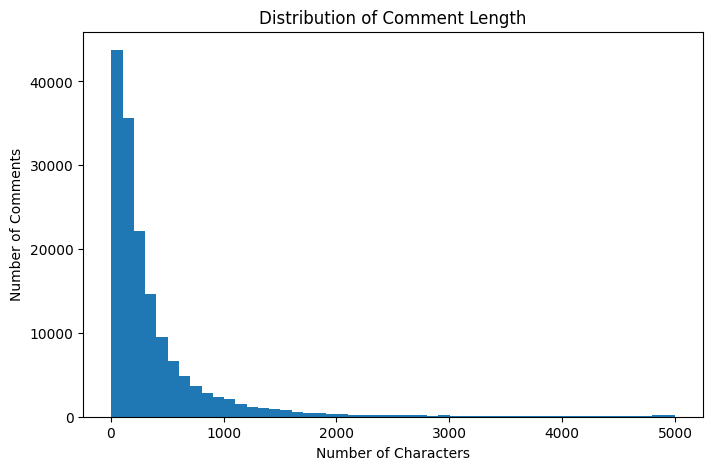

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df["char_count"], bins=50)
plt.title("Distribution of Comment Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Comments")
plt.show()

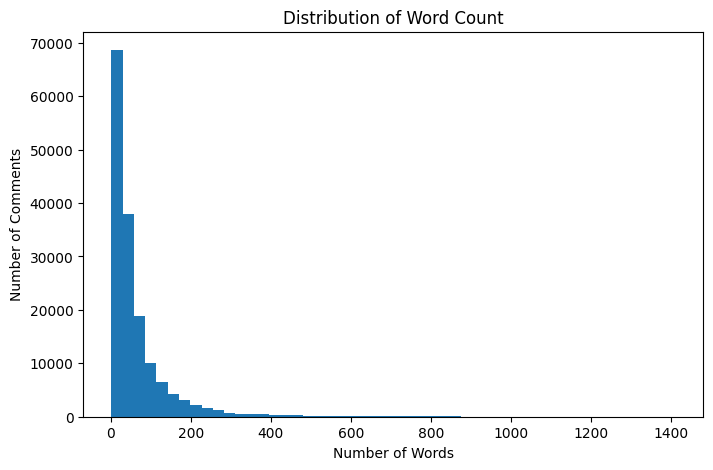

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=50)
plt.title("Distribution of Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Comments")
plt.show()

### Compare word count for toxic and non-toxic comments

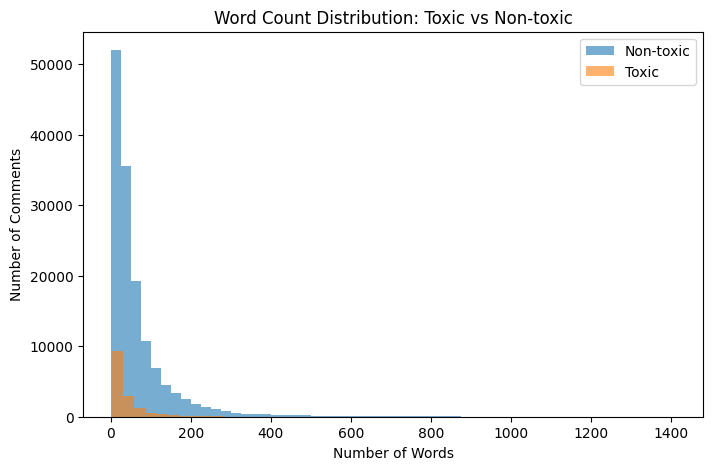

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["toxic"] == 0]["word_count"],
    bins=50,
    alpha=0.6,
    label="Non-toxic"
)

plt.hist(
    df[df["toxic"] == 1]["word_count"],
    bins=50,
    alpha=0.6,
    label="Toxic"
)

plt.title("Word Count Distribution: Toxic vs Non-toxic")
plt.xlabel("Number of Words")
plt.ylabel("Number of Comments")
plt.legend()
plt.show()


#### char count in toxic vs non-toxic

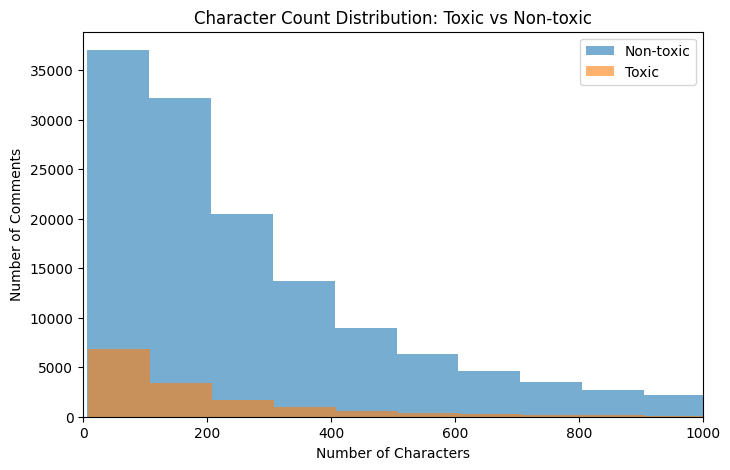

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["toxic"] == 0]["char_count"],
    bins=50,
    alpha=0.6,
    label="Non-toxic"
)

plt.hist(
    df[df["toxic"] == 1]["char_count"],
    bins=50,
    alpha=0.6,
    label="Toxic"
)
plt.xlim(0, 1000)
plt.title("Character Count Distribution: Toxic vs Non-toxic")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Comments")
plt.legend()
plt.show()


In [19]:
short_toxic = df[
    (df["toxic"] == 1) &
    (df["char_count"] <= 100)
]

print("Toxic comments with 100 characters or less:", len(short_toxic))

Toxic comments with 100 characters or less: 6450


In [20]:
df.groupby("toxic")[["char_count", "word_count"]].mean()

,char_count,word_count
toxic,,
0,407.090333,68.967874
1,297.575716,51.289787


###### dataset me toxic comments on avg non-toxic se chote h

toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64


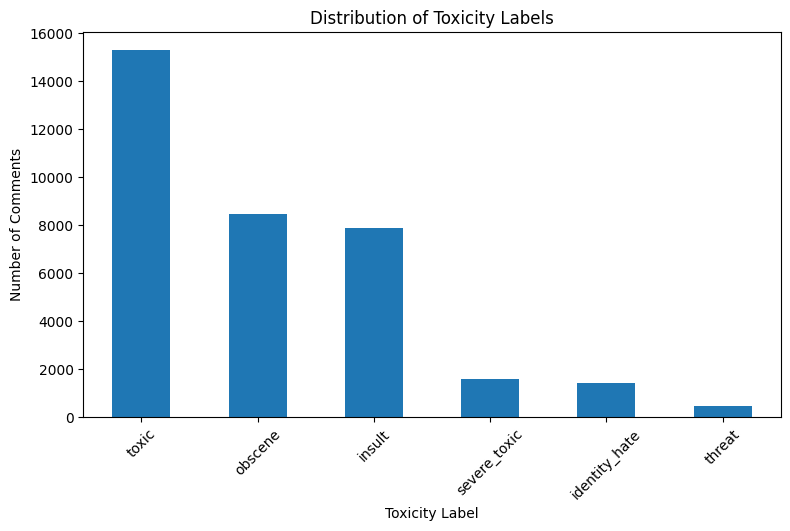

In [21]:
labels = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

label_counts = df[labels].sum().sort_values(ascending=False)

print(label_counts)

label_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Distribution of Toxicity Labels")
plt.xlabel("Toxicity Label")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.show()

In [22]:
labels = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

for label in labels:
    count = df[label].sum()
    percentage = (count / len(df)) * 100

    print(f"{label}: {count} comments ({percentage:.2f}%)")

toxic: 15294 comments (9.58%)
severe_toxic: 1595 comments (1.00%)
obscene: 8449 comments (5.29%)
threat: 478 comments (0.30%)
insult: 7877 comments (4.94%)
identity_hate: 1405 comments (0.88%)


### Feature Engineering:

In [24]:
df["uppercase_ratio"] = df["comment_text"].apply(
    lambda text: sum(char.isupper() for char in text) / len(text)
    if len(text) > 0 else 0
)

print(df[["comment_text", "uppercase_ratio"]].head())

print("\nAverage uppercase ratio:")
print(df.groupby("toxic")["uppercase_ratio"].mean())

## Har comment mein uppercase letters ka proportion calculate
# karna, phir toxic aur non-toxic comments ke average ratio
# ko compare karna.

                                        comment_text  uppercase_ratio
0  Explanation\r\nWhy the edits made under my use...         0.064151
1  D'aww! He matches this background colour I'm s...         0.071429
2  Hey man, I'm really not trying to edit war. It...         0.017167
3  "\r\nMore\r\nI can't make any real suggestions...         0.017572
4  You, sir, are my hero. Any chance you remember...         0.029851

Average uppercase ratio:
toxic
0    0.044548
1    0.113168
Name: uppercase_ratio, dtype: float64


### Note : 
Is dataset mein toxic comments average mein uppercase letters ka zyada use karte hain. uppercase_ratio potentially useful feature ho sakta hai, lekin sirf is feature se toxicity decide nahi kar sakte.

### Exclamation Count:

In [25]:
df["exclamation_count"] = df["comment_text"].apply(
    lambda text: text.count("!")
)

print("First 5 rows:")
print(df[["exclamation_count", "toxic"]].head())

print("\nAverage exclamation count by toxicity:")
print(df.groupby("toxic")["exclamation_count"].mean())

print("\nMedian exclamation count by toxicity:")
print(df.groupby("toxic")["exclamation_count"].median())

First 5 rows:
   exclamation_count  toxic
0                  0      0
1                  1      0
2                  0      0
3                  0      0
4                  0      0

Average exclamation count by toxicity:
toxic
0    0.346784
1    3.631686
Name: exclamation_count, dtype: float64

Median exclamation count by toxicity:
toxic
0    0.0
1    0.0
Name: exclamation_count, dtype: float64


Mean aur median ka difference: Kuch comments mein bahut saare ! ho sakte hain, jo toxic group ka average badha rahe hain.

In [27]:
for label, group in df.groupby("toxic"):
    total = len(group)
    comments_with_exclamation = (group["exclamation_count"] > 0).sum()
    percentage = comments_with_exclamation / total * 100

    name = "Toxic" if label == 1 else "Non-toxic"

    print(f"{name} comments:")
    print(f"  Total comments: {total}")
    print(f"  Comments with !: {comments_with_exclamation}")
    print(f"  Percentage with !: {percentage:.2f}%")

Non-toxic comments:
  Total comments: 144277
  Comments with !: 18753
  Percentage with !: 13.00%
Toxic comments:
  Total comments: 15294
  Comments with !: 4068
  Percentage with !: 26.60%


Conclusion: Toxic comments mein se 26.60% mein exclamation marks hain, jabki non-toxic comments mein ye 13.00% hai. Yaani toxic group mein ! use hone ka proportion lagbhag 2 times hai.

### Question Count:

In [29]:
df["question_count"] = df["comment_text"].apply(
    lambda text: text.count("?")
)

print("Average question count by toxicity:")
print(df.groupby("toxic")["question_count"].mean())

print("\nComments containing at least one question mark:")
for label, group in df.groupby("toxic"):
    total = len(group)
    count = (group["question_count"] > 0).sum()
    percentage = count / total * 100

    name = "Toxic" if label == 1 else "Non-toxic"
    print(f"{name}: {count} ({percentage:.2f}%)")

Average question count by toxicity:
toxic
0    0.434879
1    0.585131
Name: question_count, dtype: float64

Comments containing at least one question mark:
Non-toxic: 36697 (25.44%)
Toxic: 3787 (24.76%)


In [30]:
df["digit_count"] = df["comment_text"].apply(
    lambda text: sum(char.isdigit() for char in text)
)

print("Average digit count by toxicity:")
print(df.groupby("toxic")["digit_count"].mean())

print("\nMedian digit count by toxicity:")
print(df.groupby("toxic")["digit_count"].median())

print("\nComments containing digits:")
for label, group in df.groupby("toxic"):
    total = len(group)
    count = (group["digit_count"] > 0).sum()
    percentage = count / total * 100

    name = "Toxic" if label == 1 else "Non-toxic"
    print(f"{name}: {count} ({percentage:.2f}%)")

Average digit count by toxicity:
toxic
0    3.398289
1    2.406826
Name: digit_count, dtype: float64

Median digit count by toxicity:
toxic
0    0.0
1    0.0
Name: digit_count, dtype: float64

Comments containing digits:
Non-toxic: 47794 (33.13%)
Toxic: 3426 (22.40%)


### Summary:

In [31]:
features = [
    "char_count",
    "word_count",
    "uppercase_ratio",
    "exclamation_count",
    "question_count",
    "digit_count"
]

summary = df.groupby("toxic")[features].mean().T
summary.columns = ["Non-toxic", "Toxic"]

print(summary.round(3))

                   Non-toxic    Toxic
char_count           407.090  297.576
word_count            68.968   51.290
uppercase_ratio        0.045    0.113
exclamation_count      0.347    3.632
question_count         0.435    0.585
digit_count            3.398    2.407


### finding missing values in engineered features:

In [32]:
features = [
    "char_count",
    "word_count",
    "uppercase_ratio",
    "exclamation_count",
    "question_count",
    "digit_count"
]

print("Missing values in engineered features:")
print(df[features].isnull().sum())

print("\nData types:")
print(df[features].dtypes)

Missing values in engineered features:
char_count           0
word_count           0
uppercase_ratio      0
exclamation_count    0
question_count       0
digit_count          0
dtype: int64

Data types:
char_count             int64
word_count             int64
uppercase_ratio      float64
exclamation_count      int64
question_count         int64
digit_count            int64
dtype: object


In [33]:
print("Total duplicate comments:",
      df["comment_text"].duplicated().sum())

print("Total duplicate rows:",
      df.duplicated().sum())

Total duplicate comments: 0
Total duplicate rows: 0


In [34]:
print("Missing comment_text values:",
      df["comment_text"].isnull().sum())

print("Empty comments:",
      df["comment_text"].str.strip().eq("").sum())

print("Whitespace-only comments:",
      df["comment_text"].str.isspace().sum())

Missing comment_text values: 0
Empty comments: 0
Whitespace-only comments: 0


In [35]:
labels = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

for label in labels:
    print(f"{label}: {sorted(df[label].unique())}")

toxic: [np.int64(0), np.int64(1)]
severe_toxic: [np.int64(0), np.int64(1)]
obscene: [np.int64(0), np.int64(1)]
threat: [np.int64(0), np.int64(1)]
insult: [np.int64(0), np.int64(1)]
identity_hate: [np.int64(0), np.int64(1)]


## Target-label combinations check:

In [36]:
labels = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

df["label_count"] = df[labels].sum(axis=1)

print("Number of comments by label count:")
print(df["label_count"].value_counts().sort_index())

print("\nComments with no toxicity labels:",
      (df["label_count"] == 0).sum())

print("Comments with multiple toxicity labels:",
      (df["label_count"] > 1).sum())

Number of comments by label count:
label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64

Comments with no toxicity labels: 143346
Comments with multiple toxicity labels: 9865


In [37]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

df["any_toxic"] = (df[labels].sum(axis=1) > 0).astype(int)

print(df["any_toxic"].value_counts())
print(df["any_toxic"].value_counts(normalize=True) * 100)

any_toxic
0    143346
1     16225
Name: count, dtype: int64
any_toxic
0    89.832112
1    10.167888
Name: proportion, dtype: float64


## TF-IDF and Text Preproessing

In [38]:
from sklearn.model_selection import train_test_split

X = df["comment_text"].fillna("")
y = df["any_toxic"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [69]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [70]:
y_pred = model.predict(X_test_tfidf)

In [71]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Toxic", "Toxic"]
))

              precision    recall  f1-score   support

   Non-Toxic       0.96      0.99      0.98     28670
       Toxic       0.93      0.61      0.74      3245

    accuracy                           0.96     31915
   macro avg       0.94      0.80      0.86     31915
weighted avg       0.95      0.96      0.95     31915



In [72]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[28510   160]
 [ 1257  1988]]


In [73]:
y_prob = model.predict_proba(X_test_tfidf)[:, 1]

print(y_prob[:10])

[0.00727966 0.01820804 0.86444733 0.01302713 0.02108366 0.05491663
 0.09152612 0.00312591 0.02279001 0.01584872]


### comparing other thresholds:

In [74]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, y_pred_threshold), 3))
    print("Recall:", round(recall_score(y_test, y_pred_threshold), 3))
    print("F1-score:", round(f1_score(y_test, y_pred_threshold), 3))


Threshold: 0.3
Precision: 0.829
Recall: 0.723
F1-score: 0.772

Threshold: 0.4
Precision: 0.894
Recall: 0.667
F1-score: 0.764

Threshold: 0.5
Precision: 0.926
Recall: 0.613
F1-score: 0.737

Threshold: 0.6
Precision: 0.945
Recall: 0.562
F1-score: 0.705


In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.30, 0.31, 0.32, 0.33, 0.34,
                  0.35, 0.36, 0.37, 0.38, 0.39, 0.40]:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold:.2f}")
    print("Precision:", round(precision_score(y_test, y_pred_threshold), 3))
    print("Recall:", round(recall_score(y_test, y_pred_threshold), 3))
    print("F1-score:", round(f1_score(y_test, y_pred_threshold), 3))


Threshold: 0.30
Precision: 0.829
Recall: 0.723
F1-score: 0.772

Threshold: 0.31
Precision: 0.84
Recall: 0.718
F1-score: 0.774

Threshold: 0.32
Precision: 0.848
Recall: 0.714
F1-score: 0.775

Threshold: 0.33
Precision: 0.856
Recall: 0.709
F1-score: 0.775

Threshold: 0.34
Precision: 0.863
Recall: 0.706
F1-score: 0.776

Threshold: 0.35
Precision: 0.869
Recall: 0.7
F1-score: 0.775

Threshold: 0.36
Precision: 0.874
Recall: 0.694
F1-score: 0.773

Threshold: 0.37
Precision: 0.882
Recall: 0.687
F1-score: 0.773

Threshold: 0.38
Precision: 0.888
Recall: 0.681
F1-score: 0.771

Threshold: 0.39
Precision: 0.892
Recall: 0.674
F1-score: 0.767

Threshold: 0.40
Precision: 0.894
Recall: 0.667
F1-score: 0.764


In [83]:
threshold = 0.33
y_pred = (y_prob >= threshold).astype(int)

In [84]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Toxic", "Toxic"]
))

              precision    recall  f1-score   support

   Non-Toxic       0.97      0.99      0.98     28670
       Toxic       0.86      0.71      0.78      3245

    accuracy                           0.96     31915
   macro avg       0.91      0.85      0.88     31915
weighted avg       0.96      0.96      0.96     31915



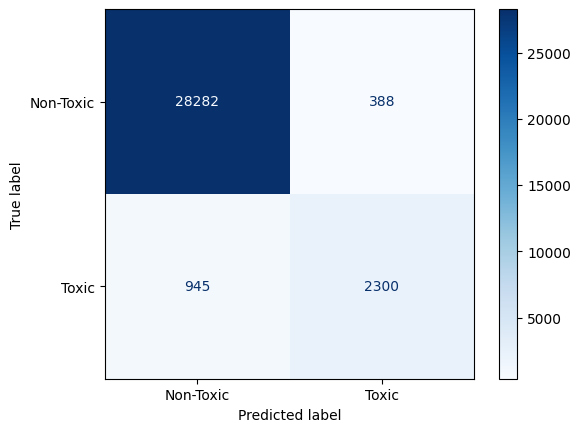

In [86]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Toxic", "Toxic"]
)

disp.plot(cmap="Blues")
plt.show()

In [87]:
import joblib

joblib.dump(model, "jigsaw_toxic_model.pkl")
joblib.dump(tfidf, "jigsaw_tfidf_vectorizer.pkl")

['jigsaw_tfidf_vectorizer.pkl']

In [88]:
import os

print(os.path.exists("jigsaw_toxic_model.pkl"))
print(os.path.exists("jigsaw_tfidf_vectorizer.pkl"))

True
True


In [89]:
import joblib

loaded_model = joblib.load("jigsaw_toxic_model.pkl")
loaded_tfidf = joblib.load("jigsaw_tfidf_vectorizer.pkl")

comment = ["You are stupid and nobody likes you"]

comment_tfidf = loaded_tfidf.transform(comment)

probability = loaded_model.predict_proba(comment_tfidf)[0][1]
prediction = int(probability >= 0.33)

print("Toxic probability:", round(probability, 3))
print("Prediction:", "Toxic" if prediction == 1 else "Non-Toxic")

Toxic probability: 0.997
Prediction: Toxic
